
# **nn.Module**

Neural network 은 데이터에 대한 연산을 수행하는 layer/Module로 구성된다.

`torch.nn` 안에 신경망을 만드는 모든 구성요소가 들어있다.
PyTorch의 모든 모듈은 `torch.nn.Module`을 상속한다.

## **1. Module 이해하기**

Pytorch에서 모듈(Module)의 의미는 다음과 같다.
1. 신경망을 구성하는 부품 하나 하나를 일컫는다.
2. 이러한 모듈 조각을 이어붙인 신경망 자체도 모듈이다.

```
import torch
import torch.nn as nn

class SimpleNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.linear = nn.Linear(3, 1)  # 입력 3개 -> 출력 1개, 은닉층 없음

    def forward(self, x):
        return self.linear(x)
```
위의 코드에서 `SimpleNN` 자체가 하나의 Module이고 내부의 `nn.Linear`도 Module이다.

모듈안에 다른 모듈들을 넣어 더 큰 모듈을 만드는 구조로 생각하면 된다.

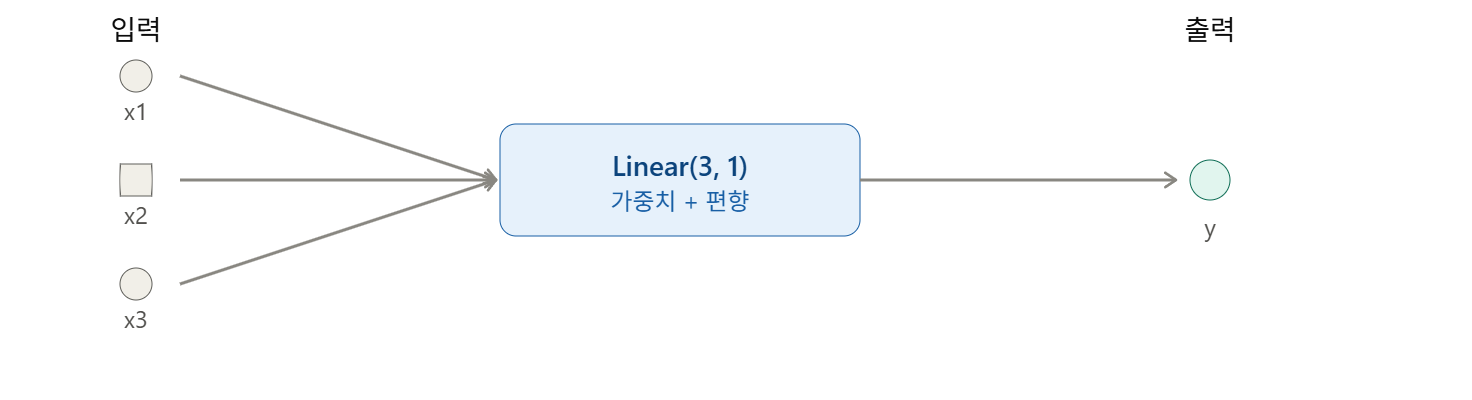


**`nn.Module`이 중요한 이유는 다음과 같다.**

단순히 함수나 멤버변수를 담는 class의 의미가 아니다.
- PyTorch가 신경망을 관리할 수 있도록 여러 기능을 함께 제공한다.
* `self.linear = nn.Linear(3,1)` 처럼 Module을 멤버 변수로 등록하면 PyTorch가 자동으로 내부 가중치를 추적한다.
* optimizer(가중치 update시 사용)에 알아서 모델의 내부 가중치 전달해 줄 수 있다.

### **1-1. __init__와 forward()의 역할**

PyTorch 모델을 만들 때 가장 중요한 두 부분이다.

**1. init()**

어떤 레이어를 사용할지 정의한다.

```
def __init__(self):
    super().__init__()

    self.linear = nn.Linear(3, 1)  # 입력 3개 -> 출력 1개, 은닉층 없음
```

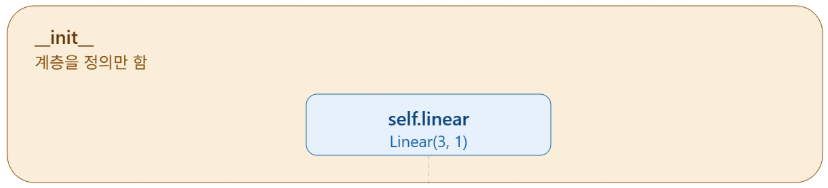

**2. forward()**

데이터가 그 레이어들을 어떤 순서로 지나가는지 정의한다.
```
def forward(self, x):
    x = self.linear(x)
    return x

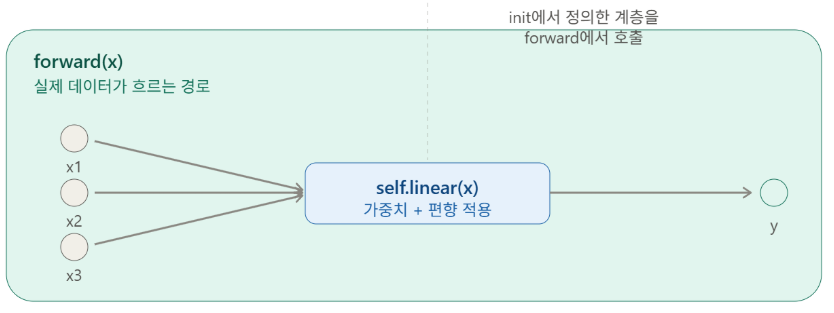

### **1-2. 모델 실행하기**

모델을 생성하고 실행시키는 방법은 아래와 같이 매우 간단하다.
```
#평균0,표준편차1인 정규분포상의 랜덤한 숫자 32*3 모양의 tensor 만들고
x = torch.randn(32, 3)

# 모델 생성하고
model = SimpleNN()

# 모델에 테스트 데이터 넣기
y = model(x)
```


### **1-3. 환경설정**

**1. 학습 장치 설정**

가속기 (GPU, CUDA, TPU..) 있으면 쓰고, 없으면 CPU를 사용하도록 설정한다.
- colab에서 runtime을 GPU로 잘 설정했다면 `.type` 으로 "cuda"가 나와야한다.

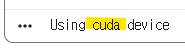

In [1]:
import os
import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

In [2]:
if torch.accelerator.is_available():
  device = torch.accelerator.current_accelerator().type # GPU가 있다면 GPU로 변환
else:
  device = "cpu"                                         # 아니면 CPU활요

print(f"device : {device}")

device : cuda


만약 "cpu"를 쓰고 있다고 나오면 오른쪽 상단 런타임변경에서 GPU로 바꿔주자

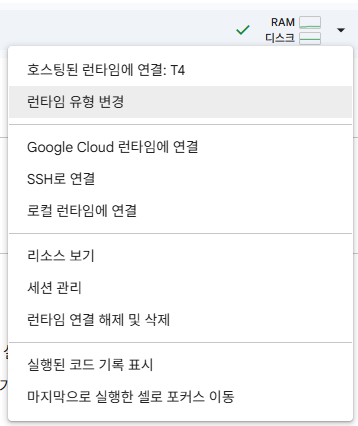

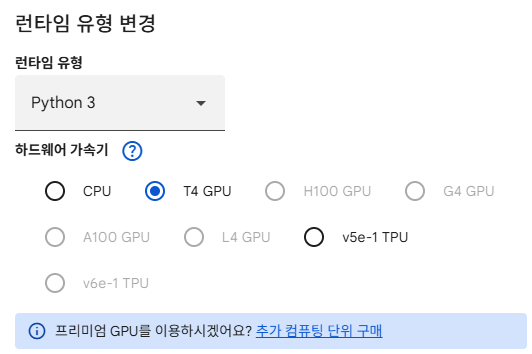

### **1-4. class 정의**

`nn.Module`을 상속해 NN을 정의하고,  `__init__` 에서 레이어 초기화(멤버 모듈 설정)한다.

`forward()` method에서 NN의 흐름을 구현해준다.
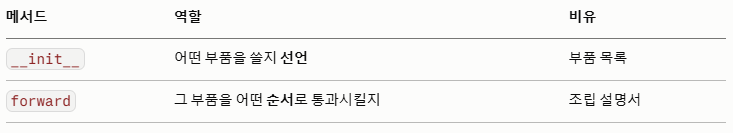


In [ ]:
class NeuralNetwork(nn.Module):
    def __init__(self):
        # 레이어와 파라미터를 관리하기 위한 내부구조 초기화
        super().__init__()

        # 2차원 데이터 -> 1차원 데이터 형태
        self.flatten = nn.Flatten()
        self.linear_relu_stack = nn.Sequential(
          # 은닉 층의 퍼셉트론 수는 보통 2의 제곱수를 쓴다
          nn.Linear(28*28, 512), # 입력(784) → 은닉층1(512)
          nn.ReLU(),             # 활성화 : ReLU
          nn.Linear(512, 512),   # 은닉층1(512) → 은닉층2(512)
          nn.ReLU(),             # 활성화 : ReLU
          nn.Linear(512, 10),    # 은닉층2(512) → 출력층(10)
        )

    def forward(self, x):
        x = self.flatten(x)
        logits = self.linear_relu_stack(x)
        return logits

모델 인스턴스를 생성하고 device로 복사한다.
- 생성된 모델을 GPU 또는 CPU로 이동시키는 작업이다.
- 데이터와 모델은 항상 같은 공간에 있어야 한다.


In [4]:
model = NeuralNetwork().to(device)
print(model) # 내가 만든 신경망 구조가 그대로 나온다.

NeuralNetwork(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (linear_relu_stack): Sequential(
    (0): Linear(in_features=784, out_features=512, bias=True)
    (1): ReLU()
    (2): Linear(in_features=512, out_features=512, bias=True)
    (3): ReLU()
    (4): Linear(in_features=512, out_features=10, bias=True)
  )
)


**모델을 사용하기 위해서는 방금 생성한 모델인스턴스에 입력 데이터를 전달 해줘야한다.**

- 데이터 역시 모델과 같은 공간(cuda)에 존재해야 한다.
- 그래야만 모델안에서 자동으로 일어나는 백그라운드 작업이 일어날 수 있고, forward()는 알아서 시작된다.


- **model.forward() 직접 호출은 절대 직접 해서는 안된다.**

In [5]:
X = torch.rand(1, 28, 28).to(device)      # 데이터를 device로 옮기기

logits = model(X)                         # 클래스별 점수(logits), shape: (1, 10)
# ReLU: 음수를 제거하는 방법으로 비선형을 만들어주는 활성화 함수
# Sigmoid: 값을 확률값으로 바궈주는 활성화 함수
# Softmax: 다중분류에 많이 사용되는 활성화 함수
#  - 여러 클래스에 대한 확률값으로 변환하는 함수
pred_prob = nn.Softmax(dim=1)(logits)   # logits → 확률 분포 (10개 합 = 1)
print(f"pred_prob: {pred_prob}")
y_pred = pred_prob.argmax(1)            # 확률이 가장 큰 클래스의 인덱스
print(f"Predicted class: {y_pred}")

pred_prob: tensor([[0.1043, 0.1019, 0.0974, 0.1057, 0.0981, 0.1016, 0.1074, 0.0930, 0.0945,
         0.0962]], device='cuda:0', grad_fn=<SoftmaxBackward0>)
Predicted class: tensor([6], device='cuda:0')


## **2. Model Layers**

**3장짜리 test용 28*28 mini-batch를 모델에게 연산시켜봅시다.**


In [6]:
input_image = torch.rand(3, 28, 28)
print(input_image.size())

torch.Size([3, 28, 28])


**만들어볼 신경망의 구조는 다음과 같다.**

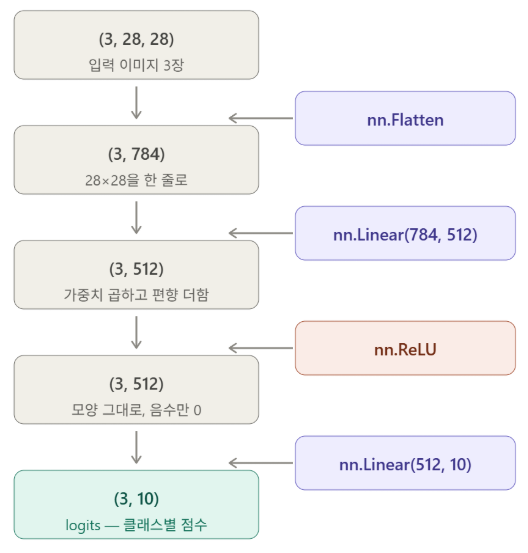

### **2-1. nn.Flatten**

nn.Flatten 레이어는 각 2D 28×28 이미지를 784개 픽셀값의 연속된 배열로 변환하며, 미니배치 차원(dim=0)은 유지된다.

- (3, 28, 28) 데이터를 통째로 펴면 (2352,)가 되어야할텐데 (3, 784)가 나온다.
- 원칙적으로 기본 동작은 0번 차원은 건드리지 않는다.
- 앞서 본 출력 Flatten(start_dim=1, end_dim=-1)이 이 설정을 보여준다.
   1번 차원부터 펴라는 뜻이다.

In [ ]:
flatten = nn.Flatten()
flat_image = flatten(input_image)
print(flat_image.size())

torch.Size([3, 784])


### **2-2 nn.Linear**
선형 레이어는 저장된 가중치와 편향을 사용해 입력에 선형 변환을 적용하는 모듈이다.

In [ ]:
layer1 = nn.Linear(in_features=28*28, out_features=10)
hidden1 = layer1(flat_image)
print(hidden1.size())

torch.Size([3, 20])


내부에서 일어나는 일은 앞에서 그린 행렬곱 연산이다.

```
출력 = 입력 @ W.T + b
(3, 784) @ (784, 20) + (20,) → (3, 20)
```

여기서 .T가 등장하는 이유는 다음과 같다.
- nn.Linear는 가중치를 (out_features, in_features) 즉 (20, 784) 모양으로 저장한다.
-  그래서 곱할 때 전치해야 차원이 맞는다.

in_features가 앞 레이어의 out_features와 일치해야 한다.
- nn.Linear(784, 512) → nn.Linear(512, 512) → nn.Linear(512, 10)처럼 숫자가 사슬처럼 이어진다.
- 이게 안 맞으면 바로 shape 에러가 발생한다.

### **2-3 nn.ReLU**

비선형 활성화 함수는 모델의 입력과 출력 사이에 복잡한 매핑을 만들어낸다.
- 선형 변환 뒤에 적용되어 비선형성을 도입하고, 신경망이 다양한 현상을 학습할 수 있게 돕는다.

**동작 자체는 매우 단순하다.**
- 튜토리얼 출력에서 -0.5757이 0.0000이 되고 0.2219는 그대로 남는 걸 볼 수 있다.
- 음수는 0으로, 양수는 그대로. shape은 전혀 바뀌지 않는다.

**왜 필요한가?**
- 선형 변환을 아무리 여러 번 쌓아도 결국 하나의 선형 변환으로 합쳐집니다. (W₂(W₁x) = (W₂W₁))
- ReLU가 없으면 512층을 쌓아도 1층짜리와 표현력이 똑같다.
- 비선형 함수가 층 사이에 끼어야 비로소 "깊은" 신경망이 된다.

그래서 결론적으로 Linear → ReLU → Linear → ReLU → Linear 패턴이 나온다.
- 마지막 Linear 뒤에는 ReLU가 없다는 것에 주목하라. (출력은 음수도 가질 수 있어야 한다.)


In [ ]:
print(f"Before ReLU: {hidden1}\n\n")
hidden1 = nn.ReLU()(hidden1)
print(f"After ReLU: {hidden1}")

Before ReLU: tensor([[ 0.0596, -0.1997,  0.2644,  0.0535,  0.3732, -0.0204, -0.0523,  0.0396,
          0.1258, -0.3973,  0.2790,  0.0018,  0.0456, -0.0855,  0.2325,  0.5128,
          0.6446, -0.0293,  0.0463,  0.2080],
        [-0.4201,  0.0215, -0.1370,  0.0854,  0.0139,  0.2915,  0.1661, -0.0108,
          0.1621, -0.5426,  0.5131, -0.2220, -0.3837, -0.4279,  0.3395,  0.4487,
          0.5206, -0.1002, -0.0399, -0.3911],
        [-0.1659, -0.0747,  0.1613,  0.3288,  0.2608, -0.0739,  0.0385,  0.0504,
          0.1955, -0.5106,  0.4186, -0.2636, -0.2362, -0.1198,  0.3229,  0.6775,
          0.7936,  0.0051,  0.1228,  0.1168]], grad_fn=<AddmmBackward0>)


After ReLU: tensor([[0.0596, 0.0000, 0.2644, 0.0535, 0.3732, 0.0000, 0.0000, 0.0396, 0.1258,
         0.0000, 0.2790, 0.0018, 0.0456, 0.0000, 0.2325, 0.5128, 0.6446, 0.0000,
         0.0463, 0.2080],
        [0.0000, 0.0215, 0.0000, 0.0854, 0.0139, 0.2915, 0.1661, 0.0000, 0.1621,
         0.0000, 0.5131, 0.0000, 0.0000, 0.0000, 0.33

### **2-3 nn.Sequential**


`nn.Sequential`은 순서가 있는 모듈 컨테이너이다.
- 데이터는 정의된 순서 그대로 모든 모듈을 통과한다.


In [ ]:
seq_modules = nn.Sequential(
    flatten,
    layer1,
    nn.ReLU(),
    nn.Linear(20, 10)
)
input_image = torch.rand(3,28,28)
logits = seq_modules(input_image)

### **2-5 nn.Softmax**

마지막 선형 레이어는 logits, 즉 [-∞, ∞] 범위의 원시 값을 반환한다.
- 그리고 이것이 nn.Softmax로 전달된다.

logits는 [0, 1] 범위로 스케일링되어 각 클래스에 대한 모델의 예측 확률이 된다.

dim 파라미터는 값들의 합이 1이 되어야 하는 차원을 가리킵니다.


In [ ]:
softmax = nn.Softmax(dim=1)
pred_probab = softmax(logits)

`dim=1`인 이유는 다음과 같다.
- (3, 10)에서 각 샘플(행)마다 10개 클래스 확률의 합이 1이 되어야 한다.
- dim=0으로 잘못 주면 샘플들끼리 합이 1이 되는 무의미한 결과가 나온다.
- 이는 생각보다 매우 흔한 실수이다.

**주의사항**
- 학습할 때는 모델에 Softmax를 넣지 말것.
- nn.CrossEntropyLoss가 내부에 이미 Softmax를 포함하고 있어서, 중복 적용하면 학습이 이상해진다.
- 모델은 logits까지만 내보내고, Softmax는 추론 결과를 사람이 읽을 때만 쓰는 게 표준이다.

## **3. Model Parameters**

신경망 내부의 많은 레이어는 파라미터화되어 있다.
- 즉 학습 중에 최적화되는 가중치와 편향을 갖고 있다.
- nn.Module을 상속하면 모델 객체 안에 정의된 모든 필드가 자동으로 추적되고, parameters()나 named_parameters()로 접근할 수 있게 된다.

In [ ]:
print(f"Model structure: {model}\n\n")

for name, param in model.named_parameters():
    print(f"Layer: {name} | Size: {param.size()} | Values : {param[:2]} \n")

Model structure: NeuralNetwork(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (linear_relu_stack): Sequential(
    (0): Linear(in_features=784, out_features=512, bias=True)
    (1): ReLU()
    (2): Linear(in_features=512, out_features=512, bias=True)
    (3): ReLU()
    (4): Linear(in_features=512, out_features=10, bias=True)
  )
)


Layer: linear_relu_stack.0.weight | Size: torch.Size([512, 784]) | Values : tensor([[ 0.0206,  0.0257, -0.0318,  ...,  0.0123, -0.0331, -0.0188],
        [ 0.0236,  0.0076,  0.0052,  ...,  0.0029,  0.0323,  0.0261]],
       device='cuda:0', grad_fn=<SliceBackward0>) 

Layer: linear_relu_stack.0.bias | Size: torch.Size([512]) | Values : tensor([ 0.0126, -0.0220], device='cuda:0', grad_fn=<SliceBackward0>) 

Layer: linear_relu_stack.2.weight | Size: torch.Size([512, 512]) | Values : tensor([[ 0.0430,  0.0087,  0.0351,  ...,  0.0118,  0.0424, -0.0075],
        [-0.0296, -0.0132, -0.0250,  ...,  0.0216,  0.0300, -0.0358]],
       device='cuda:0', grad_fn=<Sl

## **4. Pytorch Documentation**

-   [torch.nn API](https://pytorch.org/docs/stable/nn.html)
